In [1]:
!pip install librosa matplotlib numpy

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import librosa

In [19]:
audio , sr = librosa.load("ring.wav",sr = None)

print("Sampling rate:", sr)
print("Number of samples:", len(audio))

Sampling rate: 44100
Number of samples: 262094


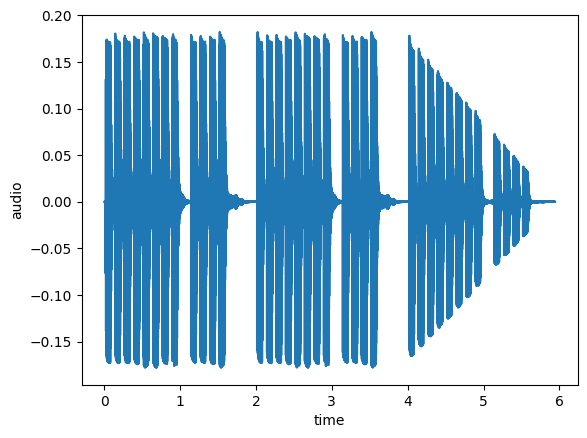

In [20]:
time = np.arange(len(audio)) / sr

plt.plot(time,audio)
plt.xlabel("time")
plt.ylabel("audio")

plt.show()

In [21]:
print(audio[:20])

[ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
  0.0000000e+00  0.0000000e+00  1.5258789e-05 -3.0517578e-05
  0.0000000e+00  4.5776367e-05 -6.1035156e-05  7.6293945e-05
 -7.6293945e-05  4.5776367e-05 -3.0517578e-05  3.0517578e-05
 -3.0517578e-05  3.0517578e-05 -1.5258789e-05  0.0000000e+00]


In [22]:
print(audio[99990:100000])

[-0.00154114 -0.00167847 -0.00177002 -0.00180054 -0.00187683 -0.00187683
 -0.00201416 -0.00180054 -0.00205994 -0.00205994]


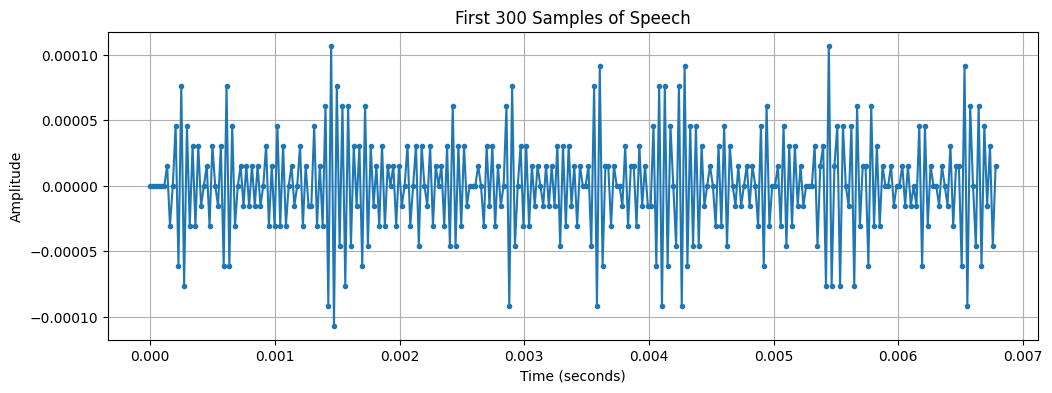

In [23]:
N = 300

time = np.arange(N) / sr

plt.figure(figsize=(12, 4))
plt.plot(time, audio[:N], marker='.')
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("First 300 Samples of Speech")
plt.grid()
plt.show()

## sampling period(Ts)

In [24]:
ts = 1 / sr
print(ts)

2.2675736961451248e-05


## FFT

In [25]:
# Perform FFT
fft = np.fft.fft(audio)

# Calculate magnitude
magnitude = np.abs(fft)

# Calculate corresponding frequencies
frequency = np.fft.fftfreq(len(audio), 1/sr)

print("magnitude:", magnitude)
print("frequency:", frequency)

magnitude: [2.2597504 2.1731617 2.2680473 ... 2.1840155 2.2680473 2.1731617]
frequency: [ 0.          0.16826024  0.33652049 ... -0.50478073 -0.33652049
 -0.16826024]


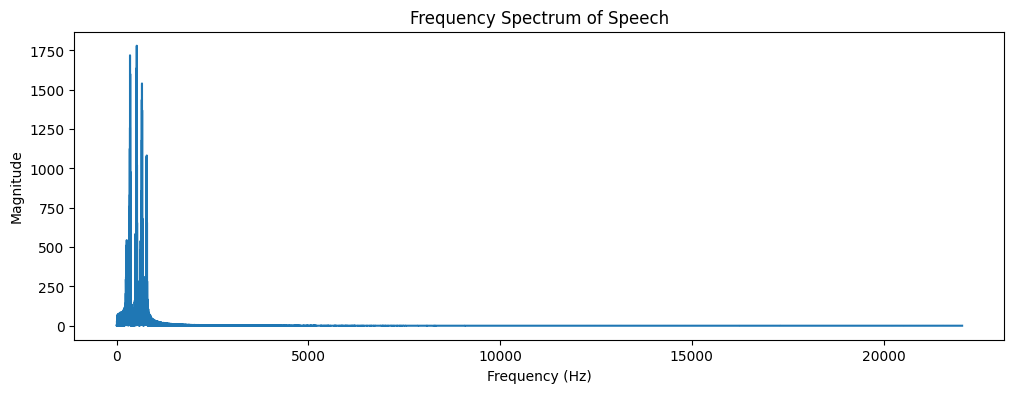

In [26]:
positive = frequency >= 0

plt.figure(figsize=(12, 4))

plt.plot(
    frequency[positive],
    magnitude[positive]
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Frequency Spectrum of Speech")

plt.show()

## STFT

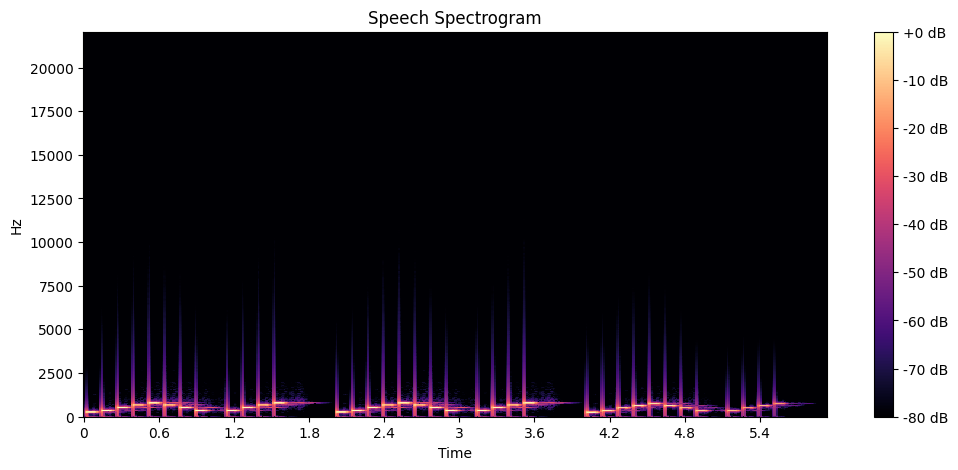

In [27]:
D = librosa.stft(audio)

magnitude = np.abs(D)

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    librosa.amplitude_to_db(magnitude, ref=np.max),
    sr=sr,
    x_axis="time",
    y_axis="hz"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Speech Spectrogram")
plt.show()

## MFCC

In [28]:
mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sr,
    n_mfcc=40
)

print("MFCC shape:", mfcc.shape)

MFCC shape: (40, 512)


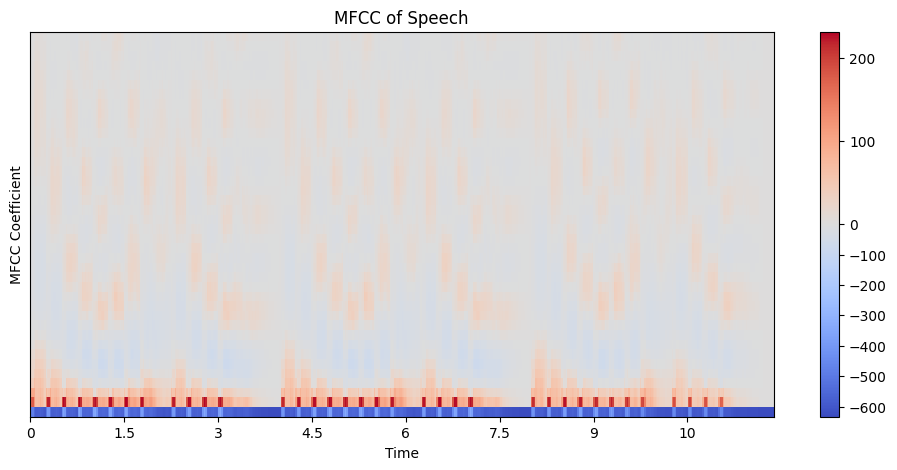

In [29]:
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mfcc,
    x_axis="time"
)

plt.colorbar()
plt.xlabel("Time")
plt.ylabel("MFCC Coefficient")
plt.title("MFCC of Speech")

plt.show()

## How does the ML will process the mfcc

In [37]:
mfcc.shape
mfcc_mean = np.mean(mfcc,axis = 1)
print(mfcc_mean)
#LSTM needs the sequence of MFCC frames because the order and changes over time contain emotional information.

[-5.4703149e+02  9.3490097e+01  4.3022720e+01  1.1886908e+01
 -6.0694256e+00 -1.8744884e+01 -2.3207802e+01 -2.1868752e+01
 -1.7259838e+01 -1.0832140e+01 -4.7848234e+00 -3.9803553e-01
  1.5905727e+00  1.4505644e+00  3.1540489e-01 -8.7053859e-01
 -1.5792491e+00 -1.6428288e+00 -1.1024666e+00 -8.9024298e-02
  1.1845090e+00  2.4094868e+00  3.2847216e+00  3.6118047e+00
  3.3687353e+00  2.7694960e+00  2.1970019e+00  2.0400629e+00
  2.4364126e+00  3.2042496e+00  3.9926782e+00  4.4228029e+00
  4.1984739e+00  3.1784508e+00  1.5441417e+00 -1.4636257e-01
 -1.2554071e+00 -1.4740269e+00 -1.0691700e+00 -6.4986521e-01]


In [39]:
#Model	Input	Why
# Decision Tree / Random Forest	(40,)	Needs fixed features
# CNN	(40,200)	Learns local patterns in MFCC
# LSTM	(40,200)	Learns time sequence
# CNN + LSTM	(40,200)	CNN extracts patterns + LSTM learns temporal changes
# CNN + LSTM + Attention	(40,200)	Learns which frames matter more

In [41]:
import pandas as pd
data = {
    'MFCC1': [-210.8, -198.7, -220.9],
    'MFCC2': [21.5, 51.9, 0.0],
    'MFCC3': [2.0, 19.0, 10.0],
    # ... add up to MFCC40 as needed
    'Emotion': ['happy', 'angry', 'sad']
}

# Creating the DataFrame
df = pd.DataFrame(data)

# Displaying the table in Jupyter Notebook
display(df)

,MFCC1,MFCC2,MFCC3,Emotion
0,-210.8,21.5,2.0,happy
1,-198.7,51.9,19.0,angry
2,-220.9,0.0,10.0,sad
